In [1]:
import torch
from PIL import Image
from transformers import pipeline
from google.colab import files
import matplotlib.pyplot as plt
import io
import pandas as pd

In [2]:
MODEL_NAME = "Organika/sdxl-detector"

detector = pipeline(
    "image-classification",
    model=MODEL_NAME,
    device=0 if torch.cuda.is_available() else -1
)

print("Model loaded successfully.")

config.json:   0%|          | 0.00/1.13k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  347MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/337 [00:00<?, ?B/s]

Model loaded successfully.


Saving PurePasture Fresh Cow Milk Carton.png to PurePasture Fresh Cow Milk Carton.png


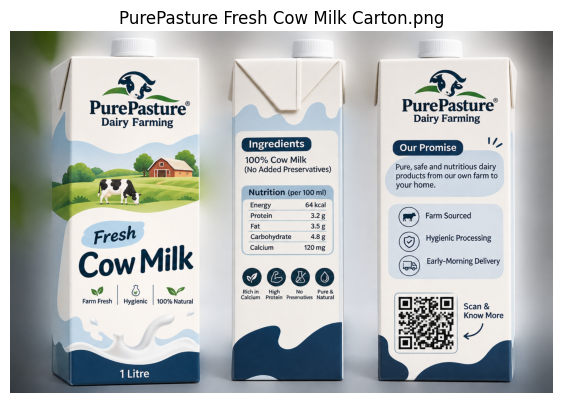

In [3]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

file_name = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[file_name])).convert("RGB")

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")
plt.title(file_name)
plt.show()

In [4]:
results = detector(image)
results_df = pd.DataFrame(results)
display(results_df)

,label,score
0,artificial,0.827845
1,human,0.172155


In [5]:
def interpret_result(results):
    ai_terms = ("fake", "ai", "artificial", "generated", "synthetic")
    real_terms = ("real", "human", "authentic", "natural", "photo")

    ai_score = sum(item["score"] for item in results if any(term in item["label"].lower() for term in ai_terms))
    real_score = sum(item["score"] for item in results if any(term in item["label"].lower() for term in real_terms))

    if ai_score == 0 and real_score == 0:
        best = max(results, key=lambda item: item["score"])
        return "Model output needs manual interpretation", best["label"], best["score"]

    if ai_score >= real_score:
        return "Likely AI-generated", "AI-related score", ai_score

    return "Likely camera-created / real", "Real-related score", real_score

prediction, score_type, confidence = interpret_result(results)

print("Detection result:", prediction)
print(f"{score_type}: {confidence:.2%}")


Detection result: Likely AI-generated
AI-related score: 82.78%
This is an estimated model prediction, not a guarantee of authenticity.
